In [1]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("Ready")

Ready


In [2]:
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

patients = pd.read_csv(
    "data/dataset",
    compression="zip",
    header=None,
    names=columns,
)

patients.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset size:", patients.shape)
print("\nFirst patient's measurements:")
print(patients.iloc[0])

Dataset size: (768, 9)

First patient's measurements:
Pregnancies                   6.000
Glucose                     148.000
BloodPressure                72.000
SkinThickness                35.000
Insulin                       0.000
BMI                          33.600
DiabetesPedigreeFunction      0.627
Age                          50.000
Outcome                       1.000
Name: 0, dtype: float64


In [4]:
patients["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [5]:
measurements = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

(patients[measurements] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [6]:
import numpy as np

for column in measurements:
    patients[column] = patients[column].replace(0, np.nan)

In [7]:
patients[measurements].isna().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [8]:
X = patients.drop(columns=["Outcome"])
y = patients["Outcome"]

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [10]:
from sklearn.pipeline import Pipeline

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

In [11]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
)

print("Each round:", scores)
print("Average accuracy:", scores.mean())

Each round: [0.7804878  0.7804878  0.76422764 0.7804878  0.80327869]
Average accuracy: 0.7817939490870318


In [12]:
recall_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="recall",
)

print("Recall each round:", recall_scores)
print("Average recall:", recall_scores.mean())

Recall each round: [0.65116279 0.58139535 0.55813953 0.48837209 0.64285714]
Average recall: 0.5843853820598006


In [13]:
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
    )),
])

In [14]:
forest_recall = cross_val_score(
    forest_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="recall",
)

print("Recall each round:", forest_recall)
print("Average recall:", forest_recall.mean())

Recall each round: [0.55813953 0.62790698 0.55813953 0.51162791 0.66666667]
Average recall: 0.5844961240310077


In [15]:
forest_accuracy = cross_val_score(
    forest_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
)

print("Accuracy each round:", forest_accuracy)
print("Average accuracy:", forest_accuracy.mean())

Accuracy each round: [0.71544715 0.79674797 0.7398374  0.78861789 0.80327869]
Average accuracy: 0.7687858190057311


In [16]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
)

In [17]:
from sklearn.model_selection import cross_validate

xgb_results = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring=["accuracy", "recall"],
)

print("Average accuracy:", xgb_results["test_accuracy"].mean())
print("Average recall:", xgb_results["test_recall"].mean())

Average accuracy: 0.7573903771824602
Average recall: 0.5937984496124031


In [18]:
from sklearn.model_selection import GridSearchCV

settings = {
    "model__C": [0.01, 0.1, 1, 10, 100],
}

search = GridSearchCV(
    logistic_pipeline,
    param_grid=settings,
    cv=5,
    scoring={"accuracy": "accuracy", "recall": "recall"},
    refit="accuracy",
)

search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'recall': 'recall'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0Controls the verbo

In [19]:
best_index = search.best_index_

print("Best setting:", search.best_params_)
print("Average accuracy:", search.best_score_)
print(
    "Average recall:",
    search.cv_results_["mean_test_recall"][best_index],
)

Best setting: {'model__C': 1}
Average accuracy: 0.7817939490870318
Average recall: 0.5843853820598006


In [20]:
fit_check = cross_validate(
    search.best_estimator_,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    return_train_score=True,
)

print("Training accuracy:", fit_check["train_score"].mean())
print("Validation accuracy:", fit_check["test_score"].mean())

Training accuracy: 0.7927557829549783
Validation accuracy: 0.7817939490870318


In [21]:
from sklearn.model_selection import GridSearchCV

xgb_settings = {
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.1],
    "n_estimators": [100, 200],
}

xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_settings,
    cv=5,
    scoring={"accuracy": "accuracy", "recall": "recall"},
    refit="accuracy",
    return_train_score=True,
)

xgb_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.03, 0.1], 'max_depth': [2, 3], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'recall': 'recall'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the 

In [22]:
best_index = xgb_search.best_index_
results = xgb_search.cv_results_

print("Training accuracy:", results["mean_train_accuracy"][best_index])
print("Validation accuracy:", results["mean_test_accuracy"][best_index])
print("Validation recall:", results["mean_test_recall"][best_index])


Training accuracy: 0.8159612869041114
Validation accuracy: 0.7720245235239237
Validation recall: 0.5421926910299003


In [23]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

probabilities = cross_val_predict(
    search.best_estimator_,
    X_train,
    y_train,
    cv=5,
    method="predict_proba",
)[:, 1]

In [25]:
for threshold in [0.5, 0.45, 0.4, 0.35, 0.3]:
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions
    ).ravel()

    print("Threshold:", threshold)
    print("Diabetes cases caught:", tp)
    print("Diabetes cases missed:", fn)
    print("False alarms:", fp)
    print()

Threshold: 0.5
Diabetes cases caught: 125
Diabetes cases missed: 89
False alarms: 45

Threshold: 0.45
Diabetes cases caught: 133
Diabetes cases missed: 81
False alarms: 53

Threshold: 0.4
Diabetes cases caught: 143
Diabetes cases missed: 71
False alarms: 67

Threshold: 0.35
Diabetes cases caught: 149
Diabetes cases missed: 65
False alarms: 85

Threshold: 0.3
Diabetes cases caught: 166
Diabetes cases missed: 48
False alarms: 116



In [26]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

statistics = []

for threshold in [0.5, 0.45, 0.4, 0.35, 0.3]:
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions
    ).ravel()

    statistics.append({
        "Threshold": threshold,
        "Accuracy (%)": accuracy_score(y_train, predictions) * 100,
        "Recall (%)": recall_score(y_train, predictions) * 100,
        "Precision (%)": precision_score(y_train, predictions) * 100,
        "Caught": tp,
        "Missed": fn,
        "False alarms": fp,
        "Correct negatives": tn,
    })

pd.DataFrame(statistics).round(1)

,Threshold,Accuracy (%),Recall (%),Precision (%),Caught,Missed,False alarms,Correct negatives
0,0.5,78.2,58.4,73.5,125,89,45,355
1,0.4,78.2,62.1,71.5,133,81,53,347
2,0.4,77.5,66.8,68.1,143,71,67,333
3,0.4,75.6,69.6,63.7,149,65,85,315
4,0.3,73.3,77.6,58.9,166,48,116,284


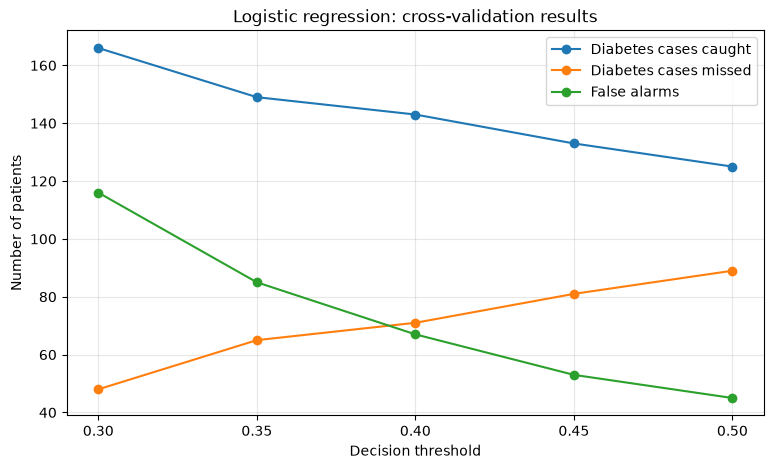

In [27]:
import matplotlib.pyplot as plt

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]
caught = []
missed = []
false_alarms = []

for threshold in thresholds:
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions
    ).ravel()

    caught.append(tp)
    missed.append(fn)
    false_alarms.append(fp)

plt.figure(figsize=(9, 5))

plt.plot(thresholds, caught, marker="o", label="Diabetes cases caught")
plt.plot(thresholds, missed, marker="o", label="Diabetes cases missed")
plt.plot(thresholds, false_alarms, marker="o", label="False alarms")

plt.xlabel("Decision threshold")
plt.ylabel("Number of patients")
plt.title("Logistic regression: cross-validation results")
plt.xticks(thresholds)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

final_threshold = 0.40
final_model = search.best_estimator_

final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= final_threshold).astype(int)

print("Test accuracy:", accuracy_score(y_test, test_predictions))
print("Test recall:", recall_score(y_test, test_predictions))
print("Test precision:", precision_score(y_test, test_predictions, zero_division=0))

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions).ravel()

print("Diabetes cases caught:", tp)
print("Diabetes cases missed:", fn)
print("False alarms:", fp)
print("Correct negatives:", tn)

Test accuracy: 0.7337662337662337
Test recall: 0.6481481481481481
Test precision: 0.6140350877192983
Diabetes cases caught: 35
Diabetes cases missed: 19
False alarms: 22
Correct negatives: 78


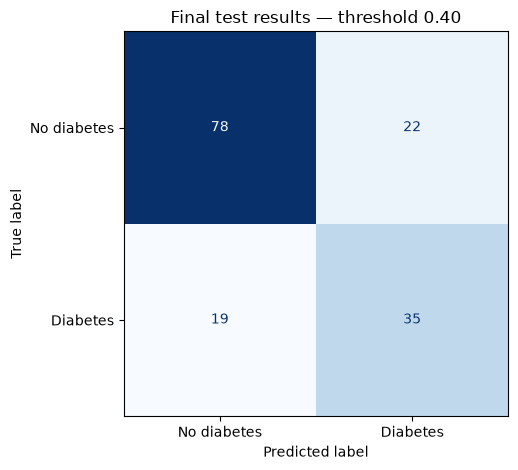

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues",
    colorbar=False,
)

plt.title("Final test results — threshold 0.40")
plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path
import joblib

Path("artifacts").mkdir(exist_ok=True)

model_bundle = {
    "pipeline": final_model,
    "threshold": final_threshold,
    "columns": X_train.columns.tolist(),
    "zero_as_missing": measurements,
}

joblib.dump(model_bundle, "artifacts/diabetes_model.joblib")

['artifacts/diabetes_model.joblib']

In [32]:
example = X_test.iloc[[0]]

display(example)

example_score = final_model.predict_proba(example)[0, 1]

print("Model score:", f"{example_score:.1%}")
print("Predicted class:", int(example_score >= final_threshold))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40


Model score: 61.0%
Predicted class: 1
